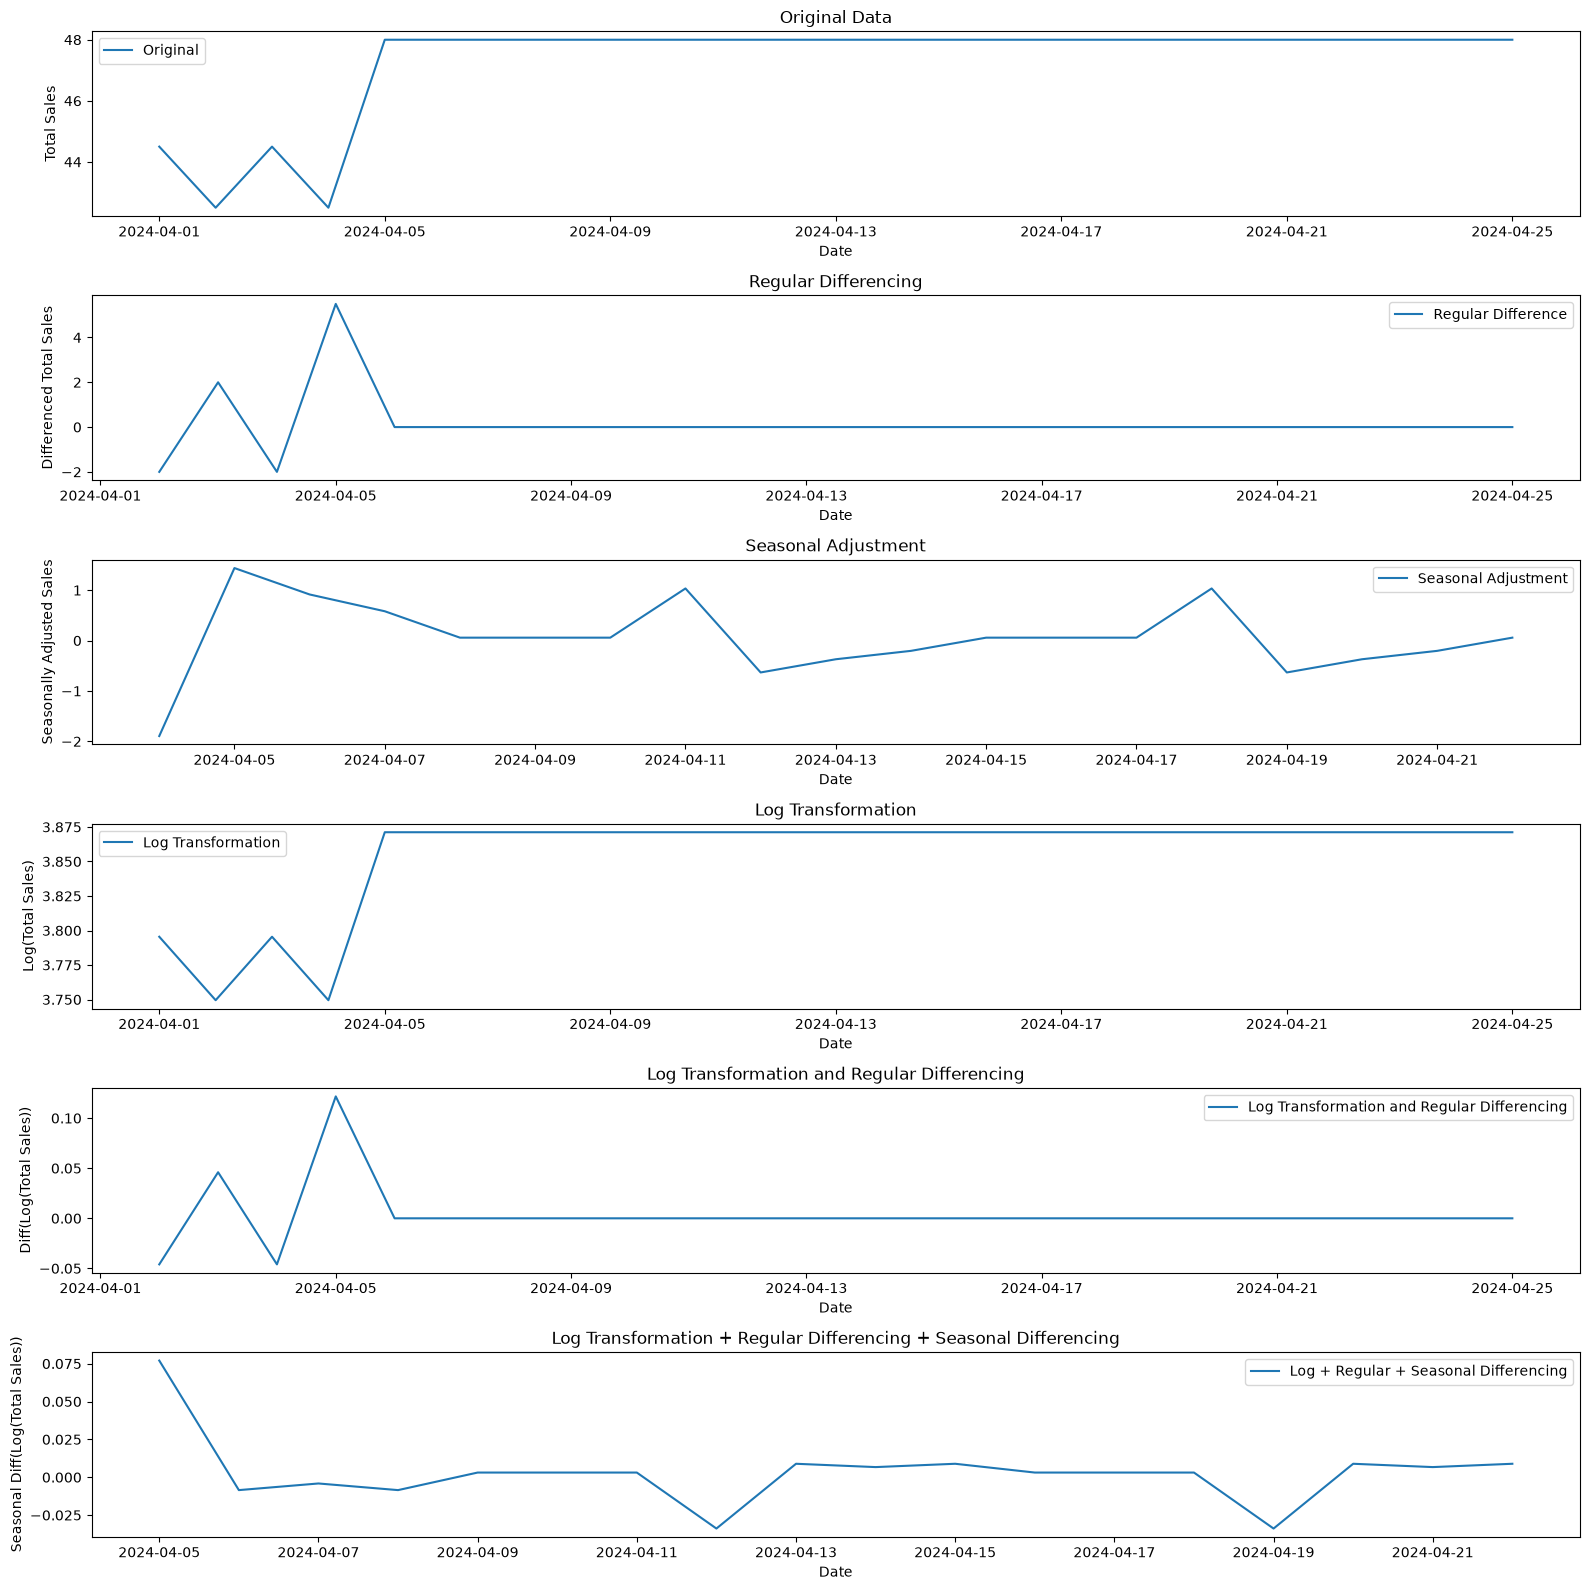

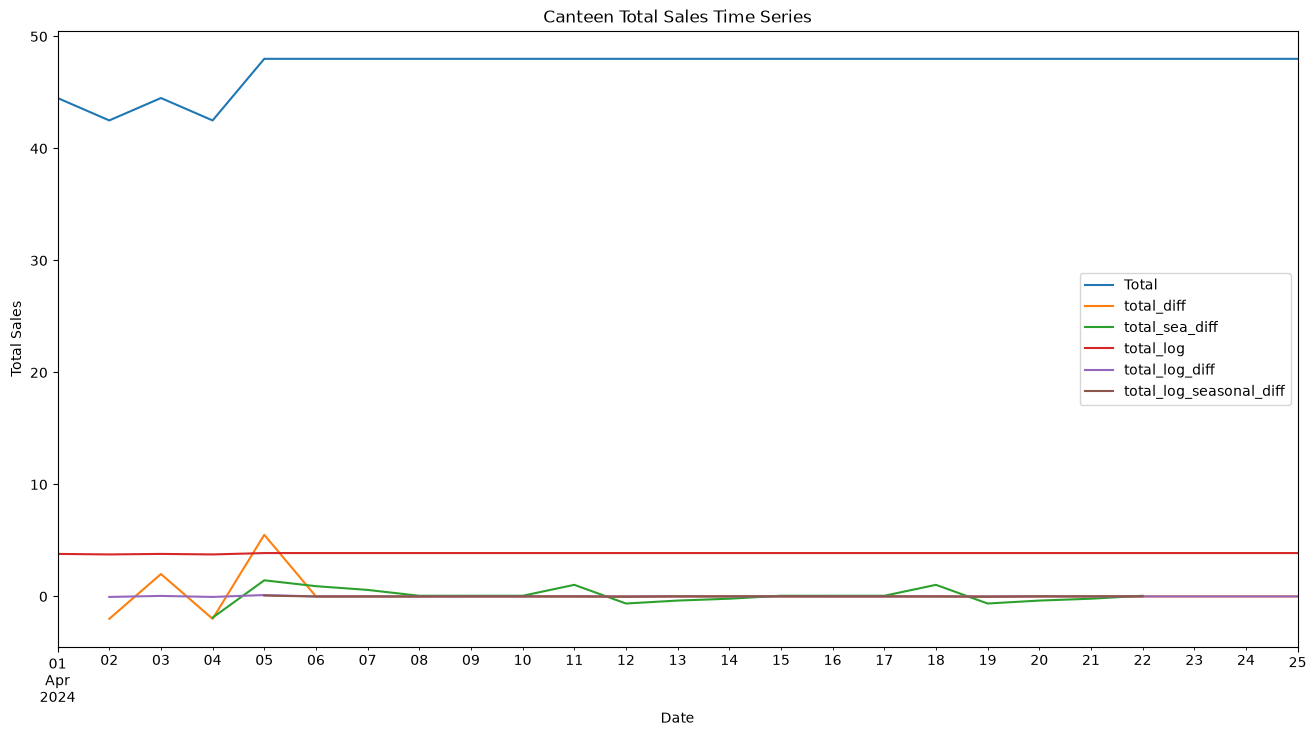

In [12]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from statsmodels.tsa.seasonal import seasonal_decompose

# Read dataset
data = pd.read_csv("C:\\Users\\acer\\Downloads\\canteen datasets\\canteen_shop_data.csv")

# Convert Date column to datetime
data['Date'] = pd.to_datetime(data['Date'])

# Make Total numeric
data['Total'] = pd.to_numeric(data['Total'], errors='coerce')

# Remove missing values
data = data.dropna(subset=['Date', 'Total'])

# Combine all transactions for each date
data = data.groupby('Date')['Total'].sum().to_frame()

# Sort by date
data = data.sort_index()

# Regular Differencing
data['total_diff'] = data['Total'].diff()

# Seasonal Decomposition
result = seasonal_decompose(
    data['Total'],
    model='additive',
    period=7
)

# Seasonal Adjustment
data['total_sea_diff'] = result.resid

# Log Transformation
data['total_log'] = np.log(data['Total'])

# Log + Regular Differencing
data['total_log_diff'] = data['total_log'].diff()

# Create separate data for decomposition
log_diff_data = data['total_log_diff'].dropna()

# Seasonal decomposition of log difference
result2 = seasonal_decompose(
    log_diff_data,
    model='additive',
    period=7
)

# Store result directly
data['total_log_seasonal_diff'] = np.nan

data.loc[
    result2.resid.index,
    'total_log_seasonal_diff'
] = result2.resid


# ==========================================
# PLOTS
# ==========================================

plt.figure(figsize=(16, 16))

# 1. Original Data
plt.subplot(6, 1, 1)
plt.plot(data['Total'], label='Original')
plt.legend(loc='best')
plt.title('Original Data')
plt.xlabel('Date')
plt.ylabel('Total Sales')


# 2. Regular Differencing
plt.subplot(6, 1, 2)
plt.plot(data['total_diff'], label='Regular Difference')
plt.legend(loc='best')
plt.title('Regular Differencing')
plt.xlabel('Date')
plt.ylabel('Differenced Total Sales')


# 3. Seasonal Adjustment
plt.subplot(6, 1, 3)
plt.plot(data['total_sea_diff'], label='Seasonal Adjustment')
plt.legend(loc='best')
plt.title('Seasonal Adjustment')
plt.xlabel('Date')
plt.ylabel('Seasonally Adjusted Sales')


# 4. Log Transformation
plt.subplot(6, 1, 4)
plt.plot(data['total_log'], label='Log Transformation')
plt.legend(loc='best')
plt.title('Log Transformation')
plt.xlabel('Date')
plt.ylabel('Log(Total Sales)')


# 5. Log + Regular Differencing
plt.subplot(6, 1, 5)
plt.plot(
    data['total_log_diff'],
    label='Log Transformation and Regular Differencing'
)
plt.legend(loc='best')
plt.title('Log Transformation and Regular Differencing')
plt.xlabel('Date')
plt.ylabel('Diff(Log(Total Sales))')


# 6. Log + Regular + Seasonal Differencing
plt.subplot(6, 1, 6)
plt.plot(
    data['total_log_seasonal_diff'],
    label='Log + Regular + Seasonal Differencing'
)
plt.legend(loc='best')
plt.title(
    'Log Transformation + Regular Differencing + Seasonal Differencing'
)
plt.xlabel('Date')
plt.ylabel('Seasonal Diff(Log(Total Sales))')


plt.tight_layout()
plt.show()


# Final line plot
data.plot(kind='line', figsize=(16, 8))
plt.title('Canteen Total Sales Time Series')
plt.xlabel('Date')
plt.ylabel('Total Sales')
plt.show()